# Using Framework
I am doing titanic notebook just as is did in fast ai course part 1 and will provide the link with it too https://www.kaggle.com/code/jhoward/why-you-should-use-a-framework

In [2]:
import numpy as np
import pandas as pd 
from fastai import *

In [3]:
from fastai.tabular.all import *
pd.options.display.float_format = '{:.2f}'.format
set_seed(42 )

/usr/local/python/3.14.2/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [4]:
df = pd.read_csv('train.csv')

In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S


In [6]:

df.info()
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [7]:
def add_features(df):
    df['LogFare'] = np.log1p(df['Fare'])
    df['Deck'] = df.Cabin.str[0].map(dict(A="ABC", B="ABC"
    , C="ABC", D="DE", E="DE", F="FG", G="FG"))
    df['Family'] = df['SibSp'] + df['Parch']
    df['Alone'] = (df['Family'] == 0).astype(int)
    df['TicketFreq'] = df.groupby('Ticket')['Ticket'].transform('count')
    df['Title'] = df.Name.str.split(', ', expand=True)[1].str.split('.', expand=True)[0]
    df['Title'] = df.Title.map(dict(Mr="Mr",Miss="Miss",Mrs="Mrs",Master="Master"))

add_features(df)

In [8]:
df[['LogFare', 'Deck', 'Family', 'Alone', 'TicketFreq', 'Title']].head()


,LogFare,Deck,Family,Alone,TicketFreq,Title
0,2.11,NaN,1,0,1,Mr
1,4.28,ABC,1,0,1,Mrs
2,2.19,NaN,0,1,1,Miss
3,3.99,ABC,1,0,2,Mrs
4,2.20,NaN,0,1,1,Mr


In [9]:
splits = RandomSplitter(seed=42)((df))

In [10]:
dls = TabularPandas(
    df,splits=splits,
    procs = [Categorify, FillMissing, Normalize],
    cat_names=['Sex', 'Embarked','Pclass','Deck','Title','Alone'],
    cont_names=['Age','SibSp','Parch','LogFare','TicketFreq','Family'],
    y_names='Survived',
    y_block=CategoryBlock(),
).dataloaders(path='.')

/usr/local/python/3.14.2/lib/python3.14/site-packages/fastai/torch_core.py:155: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  else as_tensor(x.values, **kwargs) if isinstance(x, (pd.Series, pd.DataFrame))


# Training model now

In [12]:
learn = tabular_learner(dls,metrics=accuracy, layers=[10,10])

<div></div>

SuggestedLRs(slide=0.0831763744354248, valley=0.0063095735386013985)

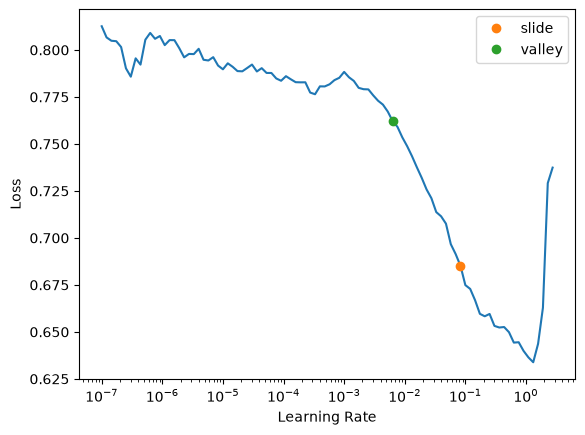

In [ ]:
learn.lr_find(suggest_funcs=(slide, valley))

<div></div>

SuggestedLRs(minimum=0.2290867567062378, steep=2.2908675418875646e-06)

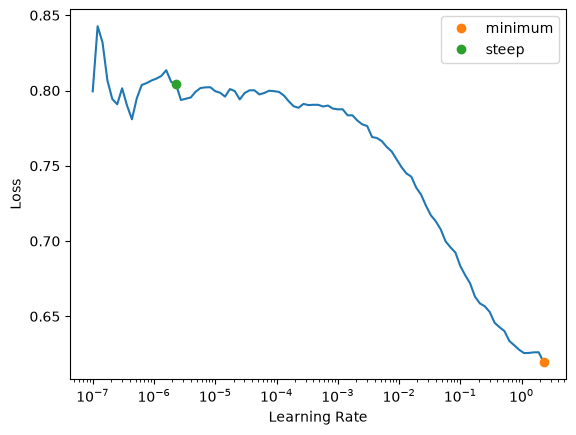

In [14]:
learn.lr_find(suggest_funcs=(minimum,steep))

In [15]:
learn.fit(16,lr=0.03)

epoch,train_loss,valid_loss,accuracy,time
0,0.529942,0.485871,0.808989,00:00
1,0.497699,0.444971,0.792135,00:00
2,0.464017,0.461428,0.825843,00:00
3,0.433285,0.426451,0.764045,00:00
4,0.415167,0.444482,0.792135,00:00
5,0.419904,0.409246,0.780899,00:00
6,0.412838,0.438606,0.780899,00:00
7,0.407373,0.479856,0.825843,00:00
8,0.403860,0.401580,0.842697,00:00
9,0.399608,0.405143,0.814607,00:00


In [16]:
learn.fit(16,lr=0.5)

epoch,train_loss,valid_loss,accuracy,time
0,0.545455,2.061229,0.786517,00:00
1,0.541241,0.959385,0.747191,00:00
2,0.564691,0.645581,0.702247,00:00
3,0.537387,0.516030,0.775281,00:00
4,0.531351,0.633402,0.567416,00:00
5,0.523309,0.723458,0.764045,00:00
6,0.534081,0.544779,0.752809,00:00
7,0.524598,0.807353,0.837079,00:00
8,0.525200,0.560413,0.808989,00:00
9,0.516616,0.617549,0.825843,00:00
